In [21]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import OneHotEncoder,LabelEncoder
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split

**EDA --> EXPLORATORY DATA ANALYSIS**

In [22]:
df = pd.read_csv("adult.csv", on_bad_lines='skip')

In [23]:
df = pd.read_csv("adult.csv", header=None, on_bad_lines='skip')

In [24]:
df.columns = ['age', 'workclass', 'fnlwgt', 'education', 'education-num', 'marital-status', 'occupation', 'relationship', 'race', 'sex', 'capital-gain', 'capital-loss', 'hours-per-week', 'native-country', 'salary']

# Strip leading/trailing spaces from column names and string values
df.columns = df.columns.str.strip()
for col in df.select_dtypes(include='object').columns:
    df[col] = df[col].str.strip()

display(df.head())

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,salary
0,39,State-gov,77516,Bachelors,13.0,Never-married,Adm-clerical,Not-in-family,White,Male,2174.0,0.0,40.0,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13.0,Married-civ-spouse,Exec-managerial,Husband,White,Male,0.0,0.0,13.0,United-States,<=50K
2,38,Private,215646,HS-grad,9.0,Divorced,Handlers-cleaners,Not-in-family,White,Male,0.0,0.0,40.0,United-States,<=50K
3,53,Private,234721,11th,7.0,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0.0,0.0,40.0,United-States,<=50K
4,28,Private,338409,Bachelors,13.0,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0.0,0.0,40.0,Cuba,<=50K


In [25]:
df.head()

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,salary
0,39,State-gov,77516,Bachelors,13.0,Never-married,Adm-clerical,Not-in-family,White,Male,2174.0,0.0,40.0,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13.0,Married-civ-spouse,Exec-managerial,Husband,White,Male,0.0,0.0,13.0,United-States,<=50K
2,38,Private,215646,HS-grad,9.0,Divorced,Handlers-cleaners,Not-in-family,White,Male,0.0,0.0,40.0,United-States,<=50K
3,53,Private,234721,11th,7.0,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0.0,0.0,40.0,United-States,<=50K
4,28,Private,338409,Bachelors,13.0,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0.0,0.0,40.0,Cuba,<=50K


In [26]:
df.shape

(32560, 15)

In [27]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32560 entries, 0 to 32559
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             32560 non-null  int64  
 1   workclass       32560 non-null  object 
 2   fnlwgt          32560 non-null  int64  
 3   education       32559 non-null  object 
 4   education-num   32559 non-null  float64
 5   marital-status  32559 non-null  object 
 6   occupation      32559 non-null  object 
 7   relationship    32559 non-null  object 
 8   race            32559 non-null  object 
 9   sex             32559 non-null  object 
 10  capital-gain    32559 non-null  float64
 11  capital-loss    32559 non-null  float64
 12  hours-per-week  32559 non-null  float64
 13  native-country  32559 non-null  object 
 14  salary          32559 non-null  object 
dtypes: float64(4), int64(2), object(9)
memory usage: 3.7+ MB


In [28]:
df.isnull().sum()

,0
age,0
workclass,0
fnlwgt,0
education,1
education-num,1
marital-status,1
occupation,1
relationship,1
race,1
sex,1


<Axes: xlabel='education', ylabel='count'>

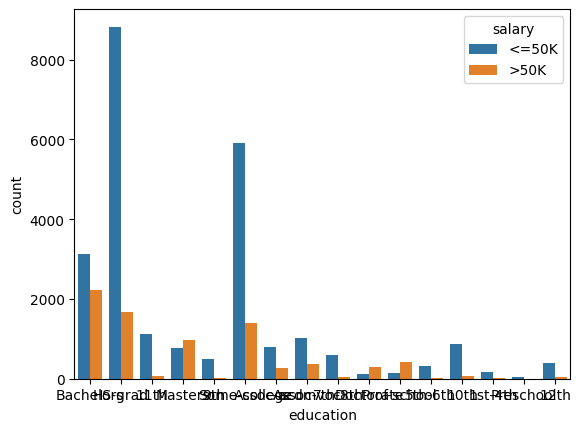

In [29]:
sns.countplot(df,x='education',hue='salary')

In [30]:
cols = df.select_dtypes(include='object').columns
for col in cols:
    print(col)
    print(df[col].value_counts())
    print('*'*120)


workclass
workclass
Private             22695
Self-emp-not-inc     2541
Local-gov            2093
?                    1836
State-gov            1298
Self-emp-inc         1116
Federal-gov           960
Without-pay            14
Never-worked            7
Name: count, dtype: int64
************************************************************************************************************************
education
education
HS-grad         10501
Some-college     7290
Bachelors        5355
Masters          1723
Assoc-voc        1382
11th             1174
Assoc-acdm       1067
10th              933
7th-8th           646
Prof-school       576
9th               514
12th              433
Doctorate         413
5th-6th           333
1st-4th           168
Preschool          51
Name: count, dtype: int64
************************************************************************************************************************
marital-status
marital-status
Married-civ-spouse       14976
Never-married      

**DATA PREPROCESSING**

In [63]:
df_cleaned = df.dropna(subset=['salary'])
# Ensure salary column only contains expected values
df_cleaned = df_cleaned[df_cleaned['salary'].isin(['<=50K', '>50K'])]
X = df_cleaned.drop(['salary','education'],axis=1)
y = df_cleaned['salary']

In [32]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer


**FEATURE ENGINEERING**

In [64]:
le = LabelEncoder()

In [34]:
num = X.select_dtypes(include='number').columns
cat = X.select_dtypes(include='object').columns

In [35]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

**PIPELINE FOR ENCODING THE DATA**

In [36]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ),
            cat
        )
    ],
    remainder="passthrough"
)

In [51]:
from sklearn.ensemble import RandomForestClassifier,ExtraTreesClassifier

**TRYING DIFFERENT ENSEMBLE MODELS**

**1. RANDOM FOREST**

In [52]:
random_forest = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1,
    class_weight="balanced"
)

In [53]:
rf_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", random_forest)
    ]
)

In [62]:
from sklearn.metrics import accuracy_score, classification_report

In [55]:
rf_pipeline.fit(X_train, y_train)

y_pred_rf = rf_pipeline.predict(X_test)

print("Random Forest Accuracy:")
print(accuracy_score(y_test, y_pred_rf))

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred_rf,
        target_names=le.classes_
    )
)

Random Forest Accuracy:
0.8570331695331695

Classification Report:
              precision    recall  f1-score   support

       <=50K       0.88      0.94      0.91      4944
        >50K       0.75      0.61      0.67      1568

    accuracy                           0.86      6512
   macro avg       0.82      0.77      0.79      6512
weighted avg       0.85      0.86      0.85      6512



In [56]:
from sklearn.ensemble import GradientBoostingClassifier,VotingClassifier,StackingClassifier

**2. GRADIENT BOOSTING**

In [57]:
gradient_boosting = GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=42
)

gb_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", gradient_boosting)
    ]
)

gb_pipeline.fit(X_train, y_train)

y_pred_gb = gb_pipeline.predict(X_test)

print("Gradient Boosting Accuracy:")
print(accuracy_score(y_test, y_pred_gb))

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred_gb,
        target_names=le.classes_
    )
)

Gradient Boosting Accuracy:
0.8702395577395577

Classification Report:
              precision    recall  f1-score   support

       <=50K       0.89      0.95      0.92      4944
        >50K       0.79      0.62      0.70      1568

    accuracy                           0.87      6512
   macro avg       0.84      0.79      0.81      6512
weighted avg       0.87      0.87      0.86      6512



**3. VOTING CLASSIFIER**

In [58]:
voting_model = VotingClassifier(
    estimators=[
        (
            "random_forest",
            RandomForestClassifier(
                n_estimators=150,
                random_state=42,
                n_jobs=-1
            )
        ),
        (
            "extra_trees",
            ExtraTreesClassifier(
                n_estimators=150,
                random_state=42,
                n_jobs=-1
            )
        ),
        (
            "gradient_boosting",
            GradientBoostingClassifier(
                n_estimators=100,
                learning_rate=0.1,
                random_state=42
            )
        )
    ],
    voting="soft"
)

voting_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", voting_model)
    ]
)

voting_pipeline.fit(X_train, y_train)

y_pred_voting = voting_pipeline.predict(X_test)

print("Voting Classifier Accuracy:")
print(accuracy_score(y_test, y_pred_voting))

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred_voting,
        target_names=le.classes_
    )
)

Voting Classifier Accuracy:
0.8619471744471745

Classification Report:
              precision    recall  f1-score   support

       <=50K       0.89      0.94      0.91      4944
        >50K       0.76      0.63      0.69      1568

    accuracy                           0.86      6512
   macro avg       0.82      0.78      0.80      6512
weighted avg       0.86      0.86      0.86      6512



**4. STACKING CLASSIFIER**

In [59]:
stacking_model = StackingClassifier(
    estimators=[
        (
            "random_forest",
            RandomForestClassifier(
                n_estimators=100,
                random_state=42,
                n_jobs=-1
            )
        ),
        (
            "extra_trees",
            ExtraTreesClassifier(
                n_estimators=100,
                random_state=42,
                n_jobs=-1
            )
        ),
        (
            "gradient_boosting",
            GradientBoostingClassifier(
                n_estimators=100,
                learning_rate=0.1,
                random_state=42
            )
        )
    ],
    final_estimator=RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ),
    n_jobs=-1
)

stacking_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", stacking_model)
    ]
)

stacking_pipeline.fit(X_train, y_train)

y_pred_stacking = stacking_pipeline.predict(X_test)

print("Stacking Classifier Accuracy:")
print(accuracy_score(y_test, y_pred_stacking))

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred_stacking,
        target_names=le.classes_
    )
)

Stacking Classifier Accuracy:
0.8485872235872236

Classification Report:
              precision    recall  f1-score   support

       <=50K       0.89      0.92      0.90      4944
        >50K       0.71      0.64      0.67      1568

    accuracy                           0.85      6512
   macro avg       0.80      0.78      0.79      6512
weighted avg       0.84      0.85      0.85      6512



**SEEING ACCURACY OF ALL MODELS**

In [60]:
results = pd.DataFrame({
    "Model": [
        "Random Forest",
        "Gradient Boosting",
        "Voting Classifier",
        "Stacking Classifier"
    ],
    "Accuracy": [
        accuracy_score(y_test, y_pred_rf),
        accuracy_score(y_test, y_pred_gb),
        accuracy_score(y_test, y_pred_voting),
        accuracy_score(y_test, y_pred_stacking)
    ]
})

results = results.sort_values(
    by="Accuracy",
    ascending=False
)

results

,Model,Accuracy
1,Gradient Boosting,0.870240
2,Voting Classifier,0.861947
0,Random Forest,0.857033
3,Stacking Classifier,0.848587


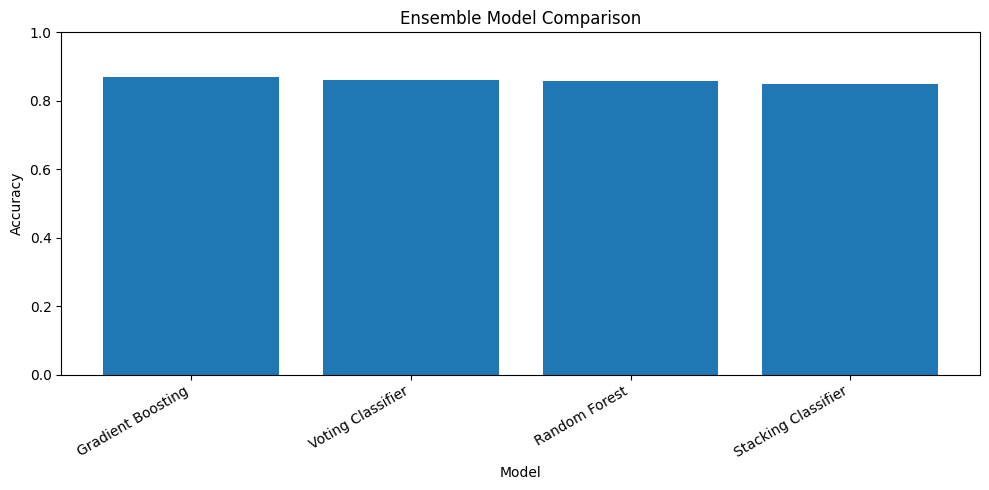

In [61]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.bar(
    results["Model"],
    results["Accuracy"]
)

plt.xlabel("Model")
plt.ylabel("Accuracy")
plt.title("Ensemble Model Comparison")

plt.xticks(
    rotation=30,
    ha="right"
)

plt.ylim(0, 1)

plt.tight_layout()
plt.show()